In [2]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
import time

In [3]:
# Verificamos la existencia de la carpeta y sus datos
def verificar_directorio(ruta_carpeta="dataset_rostros"):
    
    print(f"Verificando acceso a la carpeta: '{ruta_carpeta}'...")
    
    if not os.path.exists(ruta_carpeta):
        os.makedirs(ruta_carpeta)
        print(f"Carpeta no encontrada, creando '{ruta_carpeta}'...")
        return False
    
    subcarpetas = [f.name for f in os.scandir(ruta_carpeta) if f.is_dir()]
    
    if len(subcarpetas) == 0:
        print(f"La carpeta '{ruta_carpeta}' existe, pero está vacía (no hay subcarpetas de personas).")
        return False
    
    print(f"Se encontraron carpetas para las siguientes personas: {subcarpetas}")
    return True

verificar_directorio("dataset_rostros")
    

Verificando acceso a la carpeta: 'dataset_rostros'...
Se encontraron carpetas para las siguientes personas: ['Luis']


True

In [ ]:
# Captura de Rostros (100 fotos)

def capturar_rostros(nombre_persona, ruta_base="dataset_rostros", num_fotos_objetivo=100):
    """
    Abre la cámara web y toma automáticamente 100 fotos centradas,
    esperando un breve intervalo entre cada toma.asd
    """
    carpeta_persona = os.path.join(ruta_base, nombre_persona)
    os.makedirs(carpeta_persona, exist_ok=True)
    
    cap = cv2.VideoCapture(0)
    if not cap.isOpened():
        print("[ERROR] No se pudo abrir la cámara web.")
        return
        
    print(f"\n[INICIO] Captura AUTOMÁTICA para: '{nombre_persona}'")
    print(f"-> Se tomarán {num_fotos_objetivo} fotos automáticamente.")
    print("-> Colócate en el recuadro verde y muévete ligeramente (cambia expresión, inclina un poco la cabeza).")
    print("-> Presiona la tecla 'q' si deseas cancelar antes de tiempo.\n")
    
    for i in range(3, 0, -1):
        ret, frame = cap.read()
        if not ret: break
        h_frame, w_frame, _ = frame.shape
        tam_recuadro = 200
        x1 = (w_frame - tam_recuadro) // 2
        y1 = (h_frame - tam_recuadro) // 2
        cv2.rectangle(frame, (x1, y1), (x1 + tam_recuadro, y1 + tam_recuadro), (0, 255, 255), 2)
        cv2.putText(frame, f"Comenzando en {i}...", (x1 - 20, y1 - 20),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 255), 2)
        cv2.imshow('Captura Automatica', frame)
        cv2.waitKey(1000) # Espera 1 segundo por número
        
    contador = 0
    tiempo_espera = 0.2  # Segundos de pausa entre cada foto
    ultimo_tiempo = time.time()
    
    while contador < num_fotos_objetivo:
        ret, frame = cap.read()
        if not ret:
            print("[ERROR] No se pudo leer el fotograma de la cámara.")
            break
            
        h_frame, w_frame, _ = frame.shape
        
        # recuadro central (200x200)
        tam_recuadro = 200
        x1 = (w_frame - tam_recuadro) // 2
        y1 = (h_frame - tam_recuadro) // 2
        x2 = x1 + tam_recuadro
        y2 = y1 + tam_recuadro
        
        tiempo_actual = time.time()
        
        if (tiempo_actual - ultimo_tiempo) >= tiempo_espera:
            gris = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
            rostro_recortado = gris[y1:y2, x1:x2]
            
            contador += 1
            ruta_archivo = os.path.join(carpeta_persona, f"foto_{contador}.jpg")
            cv2.imwrite(ruta_archivo, rostro_recortado)
            print(f"[FOTO AUTOMÁTICA {contador}/{num_fotos_objetivo}] -> Guardada")
            
            ultimo_tiempo = tiempo_actual
            
        # Dibujar la interfaz en pantalla
        cv2.rectangle(frame, (x1, y1), (x2, y2), (0, 255, 0), 2)
        cv2.putText(frame, f"Capturando: {contador}/{num_fotos_objetivo}", (30, 50),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 0), 2)
        cv2.putText(frame, "Mueve ligeramente tu rostro", (30, 90),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 255), 2)
        cv2.putText(frame, "Presiona 'q' para cancelar", (30, 130),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, (200, 200, 200), 1)
        
        cv2.imshow('Captura Automatica', frame)
        
        # salida 'q'
        if cv2.waitKey(1) & 0xFF == ord('q'):
            print("[INFO] Captura cancelada por el usuario.")
            break
            
    cap.release()
    cv2.destroyAllWindows()
    print(f"\n[INFO] ¡Proceso finalizado! Se guardaron exitosamente {contador} imágenes en '{carpeta_persona}'.")


capturar_rostros(nombre_persona="Luis", num_fotos_objetivo=100)


[INICIO] Captura AUTOMÁTICA para: 'Luis'
-> Se tomarán 100 fotos automáticamente.
-> Colócate en el recuadro verde y muévete ligeramente (cambia expresión, inclina un poco la cabeza).
-> Presiona la tecla 'q' si deseas cancelar antes de tiempo.

[FOTO AUTOMÁTICA 1/100] -> Guardada
[FOTO AUTOMÁTICA 2/100] -> Guardada
[FOTO AUTOMÁTICA 3/100] -> Guardada
[FOTO AUTOMÁTICA 4/100] -> Guardada
[FOTO AUTOMÁTICA 5/100] -> Guardada
[FOTO AUTOMÁTICA 6/100] -> Guardada
[FOTO AUTOMÁTICA 7/100] -> Guardada
[FOTO AUTOMÁTICA 8/100] -> Guardada
[FOTO AUTOMÁTICA 9/100] -> Guardada
[FOTO AUTOMÁTICA 10/100] -> Guardada
[FOTO AUTOMÁTICA 11/100] -> Guardada
[FOTO AUTOMÁTICA 12/100] -> Guardada
[FOTO AUTOMÁTICA 13/100] -> Guardada
[FOTO AUTOMÁTICA 14/100] -> Guardada
[FOTO AUTOMÁTICA 15/100] -> Guardada
[FOTO AUTOMÁTICA 16/100] -> Guardada
[FOTO AUTOMÁTICA 17/100] -> Guardada
[FOTO AUTOMÁTICA 18/100] -> Guardada
[FOTO AUTOMÁTICA 19/100] -> Guardada
[FOTO AUTOMÁTICA 20/100] -> Guardada
[FOTO AUTOMÁTICA 21/10

In [8]:
def preparar_datos_entrenamiento(ruta_carpeta="dataset_rostros", ancho=100, alto=100):
    imagenes_a_matriz = []
    etiquetas = []
    
    print(f"[INFO] Leyendo imágenes desde '{ruta_carpeta}'...")
    
    if not os.path.exists(ruta_carpeta):
        print(f"[ERROR] La carpeta '{ruta_carpeta}' no existe. Asegúrate de haber capturado fotos antes.")
        return None, None, None
        
    for nombre_persona in os.listdir(ruta_carpeta):
        persona_path = os.path.join(ruta_carpeta, nombre_persona)
        
        if not os.path.isdir(persona_path):
            continue
            
        for archivo_imagen in os.listdir(persona_path):
            imagen_path = os.path.join(persona_path, archivo_imagen)
            
            # Leer la imagen en escala de grises
            img = cv2.imread(imagen_path, cv2.IMREAD_GRAYSCALE)
            if img is None:
                continue
                
            # Redimensionar para asegurar un tamaño uniforme (ej. 100x100)
            img_redimensionada = cv2.resize(img, (ancho, alto))
            
            
            vector_imagen = img_redimensionada.flatten() #FUNCIÓN DE APLANAMIENTO M x N
            
            imagenes_a_matriz.append(vector_imagen)
            etiquetas.append(nombre_persona)
            
    if len(imagenes_a_matriz) == 0:
        print("No se encontraron imágenes válidas en el dataset.")
        return None, None, None
        
    
    #Trasponemos la matriz para que sea N x M
    X = np.array(imagenes_a_matriz).T 
    
    # Calculamos el Promedio
    rostro_promedio = np.mean(X, axis=1, keepdims=True) # FUNCIÓN PROMEDIO
    
    print(f"Se cargaron {X.shape[1]} imágenes en total.")
    print(f"Dimensión de la matriz X (Píxeles x Rostros): {X.shape}")
    print(f"Dimensión del rostro promedio: {rostro_promedio.shape}")
    
    return X, rostro_promedio, etiquetas

print("Función de procesamiento cargada correctamente.")

Función de procesamiento cargada correctamente.


<>:8: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:8: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
C:\Users\luina\AppData\Local\Temp\ipykernel_24148\3618928880.py:8: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
  plt.title("Rostro Promedio ($\mu$)")


[INFO] Leyendo imágenes desde 'dataset_rostros'...
Se cargaron 100 imágenes en total.
Dimensión de la matriz X (Píxeles x Rostros): (10000, 100)
Dimensión del rostro promedio: (10000, 1)


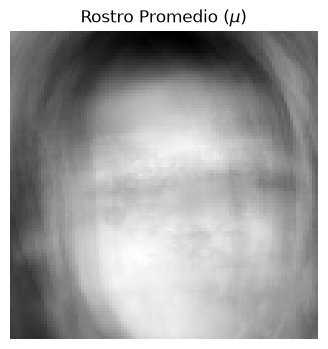

In [9]:
#Ejecución y visualización del rostro promedio
X, rostro_promedio, etiquetas = preparar_datos_entrenamiento("dataset_rostros")

if X is not None:
    # Transformamos el vector promedio de vuelta a matriz 2D (100x100) para poder dibujarlo
    plt.figure(figsize=(4, 4))
    plt.imshow(rostro_promedio.reshape(100, 100), cmap='gray')
    plt.title("Rostro Promedio ($\mu$)")
    plt.axis('off')
    plt.show()

In [10]:
# Centrado de datos y Matriz de Covarianza Reducida (L) 
# Centramos los datos
A = X - rostro_promedio

# Obtenemos el número total de imágenes (M)
M = A.shape[1]

# Calculamos la matriz de covarianza reducida: L = (A^T * A) / M
# Su dimensión será (M x M), lo que evita calcular una matriz gigantesca de píxeles x píxeles.
L = np.dot(A.T, A) / (M - 1)

print("Datos centrados y matriz L calculada con éxito")
print(f"Dimensión de la matriz A (Centrada): {A.shape}")
print(f"Dimensión de la matriz L (Covarianza Reducida): {L.shape}")

Datos centrados y matriz L calculada con éxito
Dimensión de la matriz A (Centrada): (10000, 100)
Dimensión de la matriz L (Covarianza Reducida): (100, 100)


In [11]:
# Cálculo de Autovalores, Autovectores y Eigenfaces
# Calculamos los autovalores y autovectores de la matriz simétrica L
autovalores, autovectores = np.linalg.eigh(L)

# Ordenamos los autovalores y autovectores de mayor a menor importancia (Energia)
# (np.argsort los ordena de menor a mayor, por eso usamos [::-1] para invertirlos)
indices_ordenados = np.argsort(autovalores)[::-1]
autovalores = autovalores[indices_ordenados]
autovectores = autovectores[:, indices_ordenados]

# Transformamos los autovectores de la matriz reducida a los verdaderos Eigenfaces (U)
# U = A * V
U = np.dot(A, autovectores)

# 4. Normalizamos cada Eigenface para que tengan norma unitaria (longitud 1)
for i in range(U.shape[1]):
    norma = np.linalg.norm(U[:, i])
    if norma > 0:
        U[:, i] = U[:, i] / norma

print(f"Dimensión de la matriz de (U): {U.shape} (Píxeles x Componentes)")

Dimensión de la matriz de (U): (10000, 100) (Píxeles x Componentes)


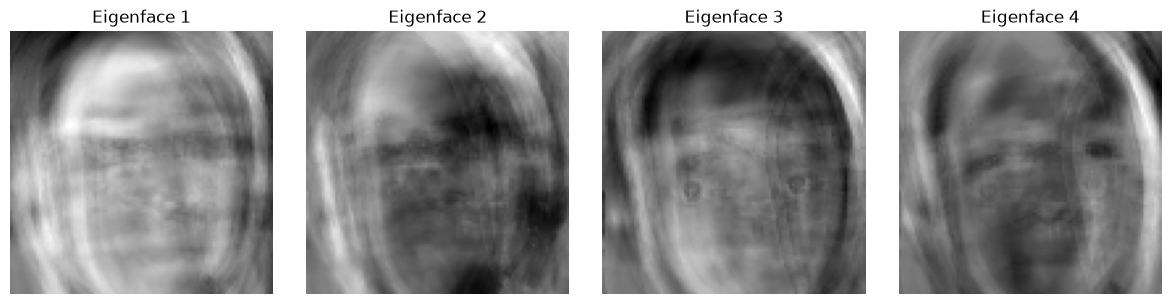

In [12]:
# Visualización de los primeros 
num_a_mostrar = min(4, U.shape[1])

plt.figure(figsize=(12, 3))
for i in range(num_a_mostrar):
    plt.subplot(1, num_a_mostrar, i + 1)
    # Reshape de vuelta a 100x100 para visualizar
    eigenface_img = U[:, i].reshape(100, 100)
    plt.imshow(eigenface_img, cmap='gray')
    plt.title(f"Eigenface {i+1}")
    plt.axis('off')

plt.tight_layout()
plt.show()

In [13]:
# Proyección del Dataset de Entrenamiento en el Subespacio 
# Definimos cuántos componentes principales (Eigenfaces) vamos a utilizar.

K = min(15, A.shape[1])

# Seleccionamos las primeras K columnas de U (los K eigenfaces más importantes)
U_k = U[:, :K]

# Proyectamos la matriz de rostros centrados (A) en el subespacio de Eigenfaces:
# P = U_k^T * A

Omega = np.dot(U_k.T, A)

print(f"Proyección completada")
print(f"Número de componentes (Eigenfaces) utilizados: {K}")
print(f"Dimensión de la matriz de pesos de entrenamiento (Omega): {Omega.shape} (K x Muestras)")

Proyección completada
Número de componentes (Eigenfaces) utilizados: 15
Dimensión de la matriz de pesos de entrenamiento (Omega): (15, 100) (K x Muestras)


In [15]:
# Reconocimiento en Tiempo Real con Umbral Inteligente

UMBRAL = 2100.0

def reconocer_con_umbral():
    cap = cv2.VideoCapture(0)
    if not cap.isOpened():
        print("[ERROR] No se pudo abrir la cámara web.")
        return
        
    print("\nReconocimiento facial activo con control de desconocidos.")
    print("-> Presiona la tecla 'q' para salir.\n")
    
    while True:
        ret, frame = cap.read()
        if not ret:
            break
            
        h_frame, w_frame, _ = frame.shape
        
        # Coordenadas del recuadro central (200x200)
        tam_recuadro = 200
        x1 = (w_frame - tam_recuadro) // 2
        y1 = (h_frame - tam_recuadro) // 2
        x2 = x1 + tam_recuadro
        y2 = y1 + tam_recuadro
        
        # Procesamiento del fotograma actual
        gris = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
        rostro_recortado = gris[y1:y2, x1:x2]
        
        img_redimensionada = cv2.resize(rostro_recortado, (100, 100))
        vector_actual = img_redimensionada.flatten().reshape(-1, 1)
        vector_centrado = vector_actual - rostro_promedio
        omega_actual = np.dot(U_k.T, vector_centrado)
        
        # Cálculo de distancias contra todo el entrenamiento
        distancias = np.linalg.norm(Omega - omega_actual, axis=0)
        indice_min = np.argmin(distancias)
        distancia_minima = distancias[indice_min]
        persona_reconocida = etiquetas[indice_min]
        
        # LÓGICA DE DECISIÓN CON EL UMBRAL
        if distancia_minima <= UMBRAL:
            texto_resultado = f"{persona_reconocida} (Dist: {int(distancia_minima)})"
            color_recuadro = (0, 255, 0)  # Verde: Identidad confirmada
        else:
            texto_resultado = f"Desconocido (Dist: {int(distancia_minima)})"
            color_recuadro = (0, 0, 255)  # Rojo: Fuera del umbral (desconocido)
            
        # Dibujar interfaz en pantalla
        cv2.rectangle(frame, (x1, y1), (x2, y2), color_recuadro, 2)
        cv2.putText(frame, texto_resultado, (x1, y1 - 10),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.6, color_recuadro, 2)
        cv2.putText(frame, f"Umbral max: {int(UMBRAL)}", (30, 40),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 1)
        cv2.putText(frame, "Presiona 'q' para salir", (30, 70),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 1)
        
        cv2.imshow('Eigenfaces - Control de Umbral', frame)
        
        if cv2.waitKey(1) & 0xFF == ord('q'):
            break
            
    cap.release()
    cv2.destroyAllWindows()
    print("[INFO] Sistema finalizado.")

# Ejecutar el reconocimiento con umbral
reconocer_con_umbral()


Reconocimiento facial activo con control de desconocidos.
-> Presiona la tecla 'q' para salir.

[INFO] Sistema finalizado.
